In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")

TRAIN_PATH = DATA_DIR / "train.csv"
VALIDATION_PATH = DATA_DIR / "validation.csv"
TEST_PATH = DATA_DIR / "test.csv"
MAPPING_PATH = DATA_DIR / "label_mapping.csv"
SUBMISSION_PATH = DATA_DIR / "sample_submission.csv"

In [53]:
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)
test_df = pd.read_csv(TEST_PATH)
label_mapping_df = pd.read_csv(MAPPING_PATH)
sample_submission_df = pd.read_csv(SUBMISSION_PATH)
train_val_df = pd.concat([train_df, val_df])


In [54]:
datasets = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df,
    "Label Mapping": label_mapping_df,
    "Sample Submission": sample_submission_df
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

Train: 58,135 rows, 3 columns
Validation: 7,267 rows, 3 columns
Test: 7,267 rows, 2 columns
Label Mapping: 10 rows, 2 columns
Sample Submission: 7,267 rows, 2 columns


In [55]:
for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nInfo:")
    df.info()



Train

Columns:
['id', 'question', 'category']

Data types:
id          int64
question      str
category      str
dtype: object

First 5 rows:


,id,question,category
0,5034,العمر ٤٢ سنة مريض ضغط باخد بيزوكارد10 اشعر بإرهاق عام دائما فذهبت لعمل تحليل سكر تراكمي فهل انا اعاني من السكري من فضلك دكتور وما نصائحك في الحياة اليومية والغذاء والعلاج,أمراض الغدد الصماء
1,44388,اعاني من فقر الدم . هل يمكنني ان القح نفسي بحقنة مضادة لفيروس كورونا ؟,الطب العام
2,37246,منذ حوالي خمسة أشهر، لاحظت نزول دم مع البراز لمدة أسبوع تقريبًا، ولم يكن مصحوبًا بأي ألم. أجريت منظارًا للقولون، وكانت النتيجة طبيعية. بالإضافة إلى ذلك، تظهر لدي أحيانًا نقاط حمراء صغيرة تحت الجلد...,الطب العام
3,3785,انا فتاه غير متزوجة عمري 34 سنه وزني 75 سنه وطولي 160 اعاني من مشكلة الحديد . حيث دائما اراجع دكتور الغدة ودائما وفي كل فحص (خمس اشهر) يطلب مني دائما فحص الحديد وفي كل مره يكون سلبي ويكتب لي حبوب ...,أمراض الدم
4,21193,تاخرت الدورة 14 يوم وعملت اختبار دم اليوم طلع حمل ضعيف وفي ميعاد الدورة نزل افرازات بنية هل هذا حمل,أمراض نسائية



Info:
<class 'pandas.DataFrame'>
RangeIndex: 58135 entries, 0 to 58134
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        58135 non-null  int64
 1   question  58135 non-null  str  
 2   category  58135 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.3 MB

Validation

Columns:
['id', 'question', 'category']

Data types:
id          int64
question      str
category      str
dtype: object

First 5 rows:


,id,question,category
0,18658,لدي من كمية افرازات قليلة خلال فتره التبويض فهل هذا يؤثر على جودة التبويض وحدوث الحمل؟,أمراض نسائية
1,4531,أنا لدي زوائد جلدية قريبة من منطقة الإبط و عدم إنتظام الدورة الشهرية و زيادة وزن منطقة البطن و كثرة الشعر الزائد و فراغ الشعر من الأمام.على ماذا تدل هذه الأعراض,أمراض الغدد الصماء
2,55306,هل العسل مع ماء دافئ مضر لطفل عمره سته شهور,امراض الاطفال
3,61346,انا نظري ضغيف اذا ظغطت على المنطقه تحت الحواجب اشوف زين لماذا,امراض العيون
4,11065,السلام عليكم انا فتاة كنت مريضة بالتهاب غدد النكافية لمدة 12 يوم والان اعاني من جفاف الفم و تقرحات الفم وصعوبة البلع لقلة اللعاب هل كل هده اعراض سببها التهاب غدد النكافية? شكر,أمراض الغدد الصماء



Info:
<class 'pandas.DataFrame'>
RangeIndex: 7267 entries, 0 to 7266
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        7267 non-null   int64
 1   question  7267 non-null   str  
 2   category  7267 non-null   str  
dtypes: int64(1), str(2)
memory usage: 170.4 KB

Test

Columns:
['id', 'question']

Data types:
id          int64
question      str
dtype: object

First 5 rows:


,id,question
0,24452,انا فتاه عمري 21سنه قبل اربع شهور كنت بوضع عصبيه بشده فارتفع عندي الضغط205/130 وصار عندي نزيف انف وفقدت الوعي وتكرر ارتفاعه لفتره والان اعاني منه بشكل دائم حتى في الراحه ما حل
1,10653,أعاني من زيادة الوزن السريعة وانا انتظم في الأكل والعلاج حبوب وانسولين ولاكن الريادة في الوزن مستمرة فما العمل ارجوالرد المقنع اريد وصفة طبية لنقصان الوزن ارجوكم ريحوني
2,16110,هل يمكن حدوث حمل مباشرةً بعد التوقف عن تناول دواء ديستونكس الخافض لارتفاع هرمون الحليب، أم يجب انتظار الدورة الشهرية التالية؟
3,40095,السلام عليكم خربشتني قطة صغيرة من الشارع ونزف منها الدم واعطوني لقاح ضد داء الكلب ولكن في العضلة الخلفية هل هو فعال او لا يجب في الكتف علما في الامس
4,47029,عندي طفلة رضيعة لم تتجاوز الشهر عندها يومين لم تتبرز وتجد صعوبة في ذلك وهي تبكي باستمرار هل من حل سريع بارك الله فيكم ضروري الرد السريع



Info:
<class 'pandas.DataFrame'>
RangeIndex: 7267 entries, 0 to 7266
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        7267 non-null   int64
 1   question  7267 non-null   str  
dtypes: int64(1), str(1)
memory usage: 113.7 KB

Label Mapping

Columns:
['category', 'label_id']

Data types:
category      str
label_id    int64
dtype: object

First 5 rows:


,category,label_id
0,أمراض العيون,0
1,الأمراض الجلدية,1
2,الطب العام,2
3,أمراض نسائية,3
4,أمراض الغدد الصماء,4



Info:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   category  10 non-null     str  
 1   label_id  10 non-null     int64
dtypes: int64(1), str(1)
memory usage: 292.0 bytes

Sample Submission

Columns:
['id', 'category']

Data types:
id            int64
category    float64
dtype: object

First 5 rows:


,id,category
0,24452,NaN
1,10653,NaN
2,16110,NaN
3,40095,NaN
4,47029,NaN



Info:
<class 'pandas.DataFrame'>
RangeIndex: 7267 entries, 0 to 7266
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        7267 non-null   int64  
 1   category  0 non-null      float64
dtypes: float64(1), int64(1)
memory usage: 113.7 KB


In [56]:
for name, df in datasets.items():
    print(f"\n{name}")

    missing = pd.DataFrame({
        "Missing Count": df.isna().sum(),
        "Missing Percentage": df.isna().mean() * 100
    })

    display(missing)


Train


,Missing Count,Missing Percentage
id,0,0.0
question,0,0.0
category,0,0.0



Validation


,Missing Count,Missing Percentage
id,0,0.0
question,0,0.0
category,0,0.0



Test


,Missing Count,Missing Percentage
id,0,0.0
question,0,0.0



Label Mapping


,Missing Count,Missing Percentage
category,0,0.0
label_id,0,0.0



Sample Submission


,Missing Count,Missing Percentage
id,0,0.0
category,7267,100.0


In [57]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum():,} duplicate rows")

Train: 0 duplicate rows
Validation: 0 duplicate rows
Test: 0 duplicate rows
Label Mapping: 0 duplicate rows
Sample Submission: 0 duplicate rows


In [85]:
for name, df in {
    "Train": train_df,
    "Validation": val_df,
    "Train-val": train_val_df,
    "Test": test_df
}.items():

    print(
        f"{name}: "
        f"{df[['question']].duplicated().sum():,} duplicate questions"
    )
    if 'category' in df.columns:
        
        print(
            f"With Category: "
            f"{df.drop(columns=['id']).duplicated().sum():,} duplicate questions"
        )
        

Train: 25 duplicate questions
With Category: 22 duplicate questions
Validation: 0 duplicate questions
With Category: 0 duplicate questions
Train-val: 31 duplicate questions
With Category: 25 duplicate questions
Test: 0 duplicate questions


In [62]:
print(train_df['id'].nunique() == train_df.shape[0],
      val_df['id'].nunique() == val_df.shape[0],
      train_val_df['id'].nunique() == train_val_df.shape[0])

True True True


In [136]:
def check_duplicated_conflict_categories(train_df, val_df):
    full_df = pd.concat([train_df.assign(split='Train'), val_df.assign(split='Val')], ignore_index=True)

    conflicting_questions = (
        full_df.groupby('question')['category']
        .nunique()
        .loc[lambda x: x > 1]
        .index
    )

    conflicts_df = (
        full_df[full_df['question'].isin(conflicting_questions)]
        .sort_values(by=['question', 'split'])
    )

    print(conflicts_df.shape)
    display(conflicts_df[['split', 'id', 'question', 'category']])
    
check_duplicated_conflict_categories(train_df, val_df)

(12, 4)


,split,id,question,category
13498,Train,41166,السلام عليكم ورحمة الله\r\nعملت فحص للسكر صائم لاكثر من شهرين ونص وكلها لاتزيد على 90 وبعد الاكل بساعتين 125-145 وبعد الاكل بثلاث ساعات 115-130 ولكن السكر التراكمي قبل شهرين 6.4 والان 7.2 هل انا م...,الطب العام
23360,Train,5537,السلام عليكم ورحمة الله\r\nعملت فحص للسكر صائم لاكثر من شهرين ونص وكلها لاتزيد على 90 وبعد الاكل بساعتين 125-145 وبعد الاكل بثلاث ساعات 115-130 ولكن السكر التراكمي قبل شهرين 6.4 والان 7.2 هل انا م...,امراض الغدد الصماء
9587,Train,41445,السلام عليكم ورحمة الله وبركاته \r\nممكن الرد على سؤالي و هو هل نسبة الهيموجلوبين ١٠.٨ يعتبر نسبة طبيعية لمرأة عمرها ٢١ سنة,الطب العام
59482,Val,2373,السلام عليكم ورحمة الله وبركاته \r\nممكن الرد على سؤالي و هو هل نسبة الهيموجلوبين ١٠.٨ يعتبر نسبة طبيعية لمرأة عمرها ٢١ سنة,امراض الدم
49476,Train,41568,انا عمري ١٧ سنه وطولي ١٦٨ سنتيمتر وانا اقصر من اخوتي بقد من ٥ الي ٧ سنتيمتر وذهبت لطبيب غدد صماء واخبرني ان مادام حدث بلوغ فلا يمكن اعطاء هرمون النمو و هذا الموضوع مؤثر بالنسبة لي ولا اعرف ان كنت ...,الطب العام
58999,Val,5849,انا عمري ١٧ سنه وطولي ١٦٨ سنتيمتر وانا اقصر من اخوتي بقد من ٥ الي ٧ سنتيمتر وذهبت لطبيب غدد صماء واخبرني ان مادام حدث بلوغ فلا يمكن اعطاء هرمون النمو و هذا الموضوع مؤثر بالنسبة لي ولا اعرف ان كنت ...,امراض الغدد الصماء
37115,Train,41344,انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه كدا مظبوطه ولا محتاج علاج لو محتاج علاج ايه العلاج المطلوب,الطب العام
42719,Train,2362,انا عملت تحليل انيميا وطلعت نسبه mchc 30 النسبه كدا مظبوطه ولا محتاج علاج لو محتاج علاج ايه العلاج المطلوب,امراض الدم
17242,Train,5633,انا عندي ارتفاع في الضغط استخدم دواء amlocard ولكن عند قياسه ارى ان هناك اختلف كبير في القرات تكون القراى الاولة 180/106 وتكون الاخيرة 150/83 هل هاذا طبيعي ام ماذ,امراض الغدد الصماء
21053,Train,22043,انا عندي ارتفاع في الضغط استخدم دواء amlocard ولكن عند قياسه ارى ان هناك اختلف كبير في القرات تكون القراى الاولة 180/106 وتكون الاخيرة 150/83 هل هاذا طبيعي ام ماذ,ارتفاع ضغط الدم


In [52]:
for name, df in {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}.items():

    empty_questions = (
        df["question"]
        .fillna("")
        .str.strip()
        .eq("")
    )

    print(f"{name}: {empty_questions.sum()} empty questions")

Train: 0 empty questions
Validation: 0 empty questions
Test: 0 empty questions


In [137]:
# 1. Identify questions with conflicting categories across Train + Val (6 questions)
combined = pd.concat([train_df, val_df], ignore_index=True)
conflicting_questions = (
    combined.groupby('question')['category']
    .nunique()
    .loc[lambda x: x > 1]
    .index
)

# 2. Drop all conflicting questions from BOTH splits
train_clean = train_df[~train_df['question'].isin(conflicting_questions)].copy()
val_clean = val_df[~val_df['question'].isin(conflicting_questions)].copy()

# 3. Drop exact duplicates (same question + same category) within Train and within Val
train_clean = train_clean.drop_duplicates(subset=['question'], keep='first').reset_index(drop=True)
val_clean = val_clean.drop_duplicates(subset=['question'], keep='first').reset_index(drop=True)

# 4. Drop any remaining Val questions that already exist in Train (prevents leakage)
val_clean = val_clean[~val_clean['question'].isin(train_clean['question'])].reset_index(drop=True)

# --- Verify 0 duplicates remain ---
print(f"Train duplicates left:     {train_clean['question'].duplicated().sum()}")
print(f"Val duplicates left:       {val_clean['question'].duplicated().sum()}")
print(f"Train-Val overlap left:    {val_clean['question'].isin(train_clean['question']).sum()}")
check_duplicated_conflict_categories(train_clean,val_clean)


Train duplicates left:     0
Val duplicates left:       0
Train-Val overlap left:    0
(0, 4)


,split,id,question,category


In [138]:
train_df = train_clean
val_df = val_clean

### Observations 1
- datatypes are correct
- no empty questions
- no duplicated rows (since each row have a unique id)
- we have 25 duplicated question in train set, 31 in train-val, 0 in other sets
- an issue in the train set that we have 3 questions duplicated with differnt categories, and in train val the number increases to 6. i removed them rather than keeping them since we have enough samples.

### Target Analysis

In [139]:
num_categories = train_df["category"].nunique()

print("Number of categories:", num_categories)
print("Labled Categories:", label_mapping_df.shape)

Number of categories: 10
Labled Categories: (10, 2)


In [140]:
category_counts = train_df["category"].value_counts()

display(category_counts.to_frame("Count"))
display(label_mapping_df['category'])

,Count
category,
امراض العيون,7982
امراض الاطفال,7980
الامراض الجلدية,7968
الطب العام,7947
امراض نسائية,7947
امراض الغدد الصماء,7458
ارتفاع ضغط الدم,3998
صحة الاسنان,3277
امراض الدم,1932


0            امراض العيون
1         الامراض الجلدية
2              الطب العام
3            امراض نسائية
4      امراض الغدد الصماء
5           امراض الاطفال
6         ارتفاع ضغط الدم
7             صحة الاسنان
8              امراض الدم
9    امراض الجهاز التنفسي
Name: category, dtype: str

seems we need to clean the categories, then recheck for duplicated values again, hope that this changes nothing

In [141]:
train_df['category'] = train_df['category'].str.replace('أ', 'ا', regex=False)
val_df['category'] = val_df['category'].str.replace('أ', 'ا', regex=False)
train_val_df = pd.concat([train_df, val_df])
label_mapping_df['category'] = label_mapping_df['category'].str.replace('أ', 'ا', regex=False)

num_categories = train_df["category"].nunique()

print("Number of categories:", num_categories)
print("Labled Categories:", label_mapping_df.shape)

category_counts = train_df["category"].value_counts()

display(category_counts.to_frame("Count"))
display(label_mapping_df['category'])

Number of categories: 10
Labled Categories: (10, 2)


,Count
category,
امراض العيون,7982
امراض الاطفال,7980
الامراض الجلدية,7968
الطب العام,7947
امراض نسائية,7947
امراض الغدد الصماء,7458
ارتفاع ضغط الدم,3998
صحة الاسنان,3277
امراض الدم,1932


0            امراض العيون
1         الامراض الجلدية
2              الطب العام
3            امراض نسائية
4      امراض الغدد الصماء
5           امراض الاطفال
6         ارتفاع ضغط الدم
7             صحة الاسنان
8              امراض الدم
9    امراض الجهاز التنفسي
Name: category, dtype: str

In [142]:
for name, df in {
    "Train": train_df,
    "Validation": val_df,
    "Train-val": train_val_df,
    "Test": test_df
}.items():

    print(
        f"{name}: "
        f"{df[['question']].duplicated().sum():,} duplicate questions"
    )
    if 'category' in df.columns:
        
        print(
            f"With Category: "
            f"{df.drop(columns=['id']).duplicated().sum():,} duplicate questions"
        )
        

Train: 0 duplicate questions
With Category: 0 duplicate questions
Validation: 0 duplicate questions
With Category: 0 duplicate questions
Train-val: 0 duplicate questions
With Category: 0 duplicate questions
Test: 0 duplicate questions


Nothing changed in duplicates, good.

In [143]:
def show_some_stats_about_df(df, df_name):
    
    category_counts = df["category"].value_counts()
    display(category_counts.to_frame("Count"))
    category_distribution = pd.DataFrame({
        "Count": category_counts,
        "Percentage": category_counts / len(train_df) * 100
    })

    display(category_distribution)
    plt.figure(figsize=(14, 7))

    sns.barplot(
        x=category_counts.values,
        y=category_counts.index,
        color="steelblue"
    )

    plt.title(f"{df_name} Data: Questions per Category")
    plt.xlabel("Number of Questions")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()
    print("Largest category:")
    print(category_counts.index[0], category_counts.iloc[0])

    print("\nSmallest category:")
    print(category_counts.index[-1], category_counts.iloc[-1])

    print("\nImbalance Ratio:")
    print(category_counts.max() / category_counts.min())

    counts = category_counts
    majority_class = counts.idxmax()
    minority_class = counts.idxmin()
    ir = counts.max() / counts.min()

    print(f"Majority Class: {majority_class} ({counts.max():,})")
    print(f"Minority Class: {minority_class} ({counts.min():,})")
    print(f"Imbalance Ratio (IR): {ir:.2f} : 1\n")

    # Optional: See how many times larger each class is compared to the smallest class
    ir_per_class = (counts / counts.min()).round(2)
    display(ir_per_class.to_frame(name='Ratio vs Smallest'))


,Count
category,
امراض العيون,7982
امراض الاطفال,7980
الامراض الجلدية,7968
الطب العام,7947
امراض نسائية,7947
امراض الغدد الصماء,7458
ارتفاع ضغط الدم,3998
صحة الاسنان,3277
امراض الدم,1932


,Count,Percentage
category,,
امراض العيون,7982,13.737436
امراض الاطفال,7980,13.733994
الامراض الجلدية,7968,13.713342
الطب العام,7947,13.677200
امراض نسائية,7947,13.677200
امراض الغدد الصماء,7458,12.835605
ارتفاع ضغط الدم,3998,6.880766
صحة الاسنان,3277,5.639887
امراض الدم,1932,3.325072


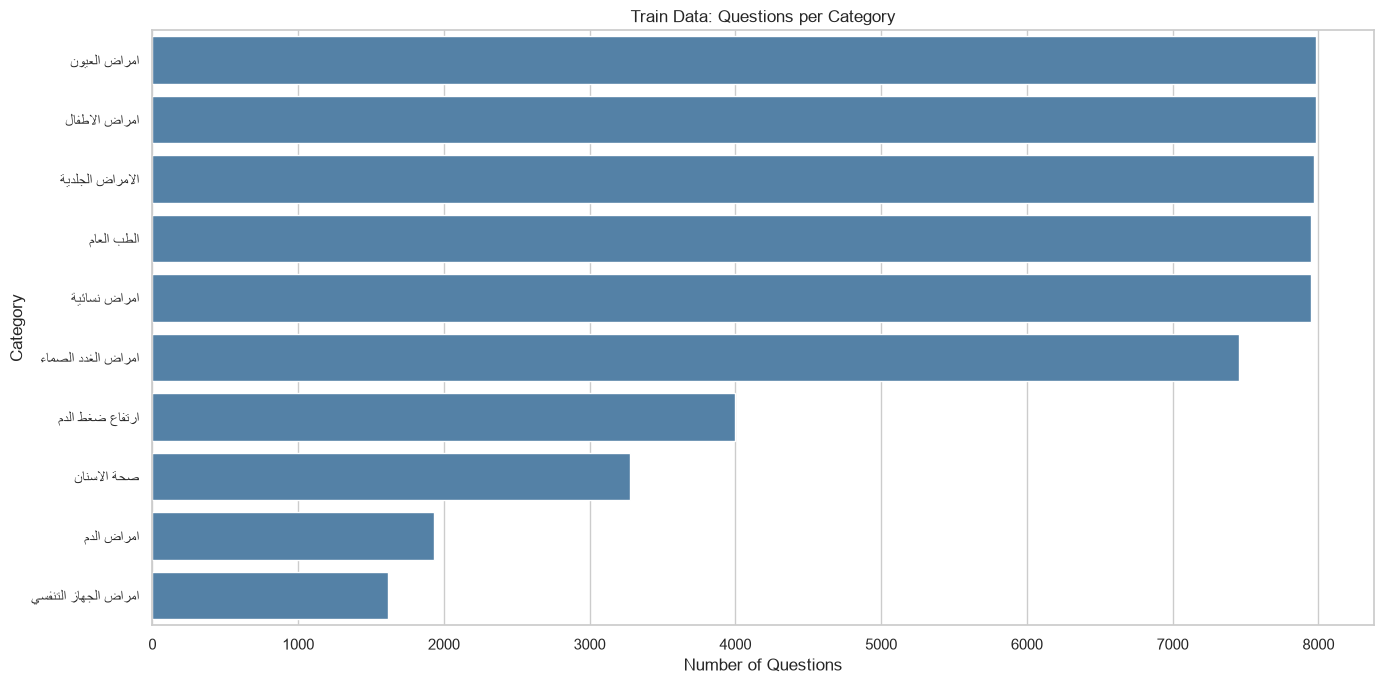

Largest category:
امراض العيون 7982

Smallest category:
امراض الجهاز التنفسي 1615

Imbalance Ratio:
4.942414860681114
Majority Class: امراض العيون (7,982)
Minority Class: امراض الجهاز التنفسي (1,615)
Imbalance Ratio (IR): 4.94 : 1



,Ratio vs Smallest
category,
امراض العيون,4.94
امراض الاطفال,4.94
الامراض الجلدية,4.93
الطب العام,4.92
امراض نسائية,4.92
امراض الغدد الصماء,4.62
ارتفاع ضغط الدم,2.48
صحة الاسنان,2.03
امراض الدم,1.20


In [144]:
show_some_stats_about_df(train_df, 'Train')

Lets check Validation

,Count
category,
امراض الاطفال,999
امراض العيون,998
الامراض الجلدية,996
امراض نسائية,994
الطب العام,994
امراض الغدد الصماء,930
ارتفاع ضغط الدم,500
صحة الاسنان,409
امراض الدم,240


,Count,Percentage
category,,
امراض الاطفال,999,1.719331
امراض العيون,998,1.717610
الامراض الجلدية,996,1.714168
امراض نسائية,994,1.710726
الطب العام,994,1.710726
امراض الغدد الصماء,930,1.600578
ارتفاع ضغط الدم,500,0.860526
صحة الاسنان,409,0.703910
امراض الدم,240,0.413052


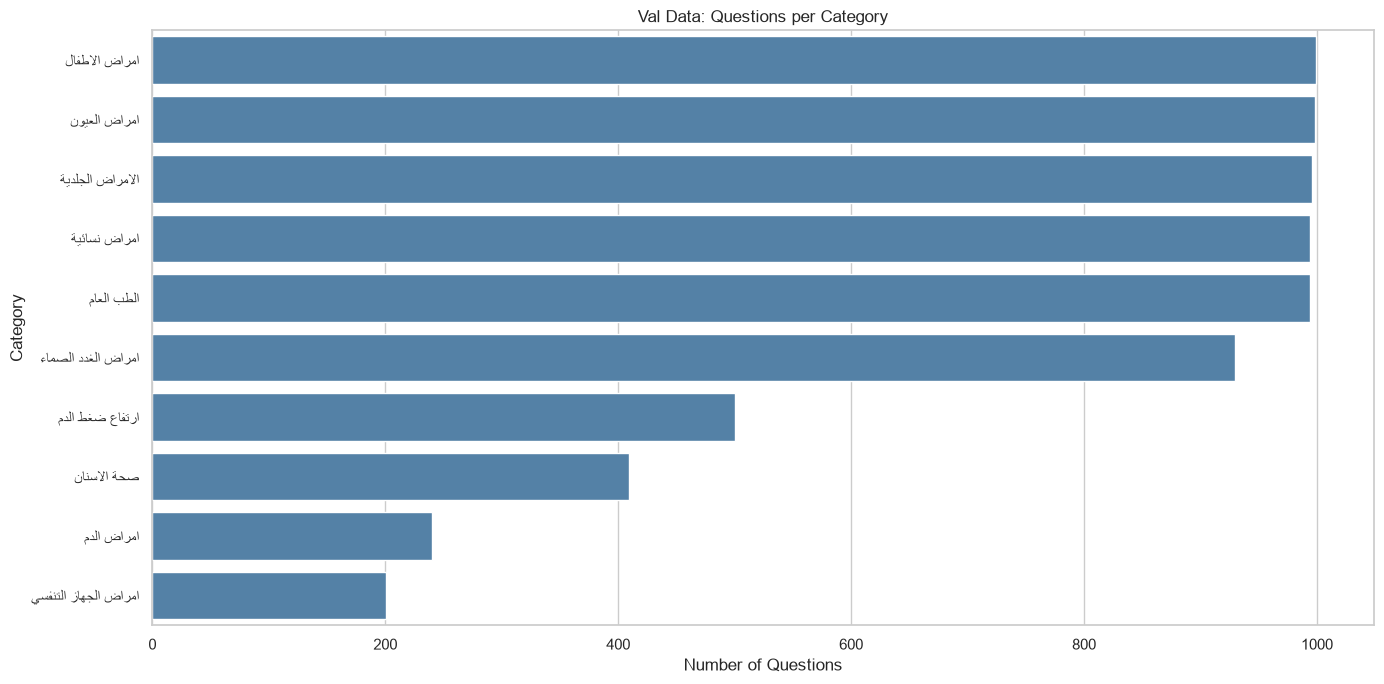

Largest category:
امراض الاطفال 999

Smallest category:
امراض الجهاز التنفسي 201

Imbalance Ratio:
4.970149253731344
Majority Class: امراض الاطفال (999)
Minority Class: امراض الجهاز التنفسي (201)
Imbalance Ratio (IR): 4.97 : 1



,Ratio vs Smallest
category,
امراض الاطفال,4.97
امراض العيون,4.97
الامراض الجلدية,4.96
امراض نسائية,4.95
الطب العام,4.95
امراض الغدد الصماء,4.63
ارتفاع ضغط الدم,2.49
صحة الاسنان,2.03
امراض الدم,1.19


In [145]:
show_some_stats_about_df(val_df,"Val")

seems they have same distrubtion, lets check

=== Summary Metrics ===
Train Total: 58,104 | Overall IR: 4.94 : 1
Val Total:   7,261 | Overall IR: 4.97 : 1



,Train Count,Val Count,Train %,Val %,Diff % (Train - Val),Train IR,Val IR
category,,,,,,,
ارتفاع ضغط الدم,3998,500,6.88,6.89,-0.01,2.48,2.49
الامراض الجلدية,7968,996,13.71,13.72,-0.01,4.93,4.96
الطب العام,7947,994,13.68,13.69,-0.01,4.92,4.95
امراض الاطفال,7980,999,13.73,13.76,-0.03,4.94,4.97
امراض الجهاز التنفسي,1615,201,2.78,2.77,0.01,1.00,1.00
امراض الدم,1932,240,3.33,3.31,0.02,1.20,1.19
امراض العيون,7982,998,13.74,13.74,0.00,4.94,4.97
امراض الغدد الصماء,7458,930,12.84,12.81,0.03,4.62,4.63
امراض نسائية,7947,994,13.68,13.69,-0.01,4.92,4.95


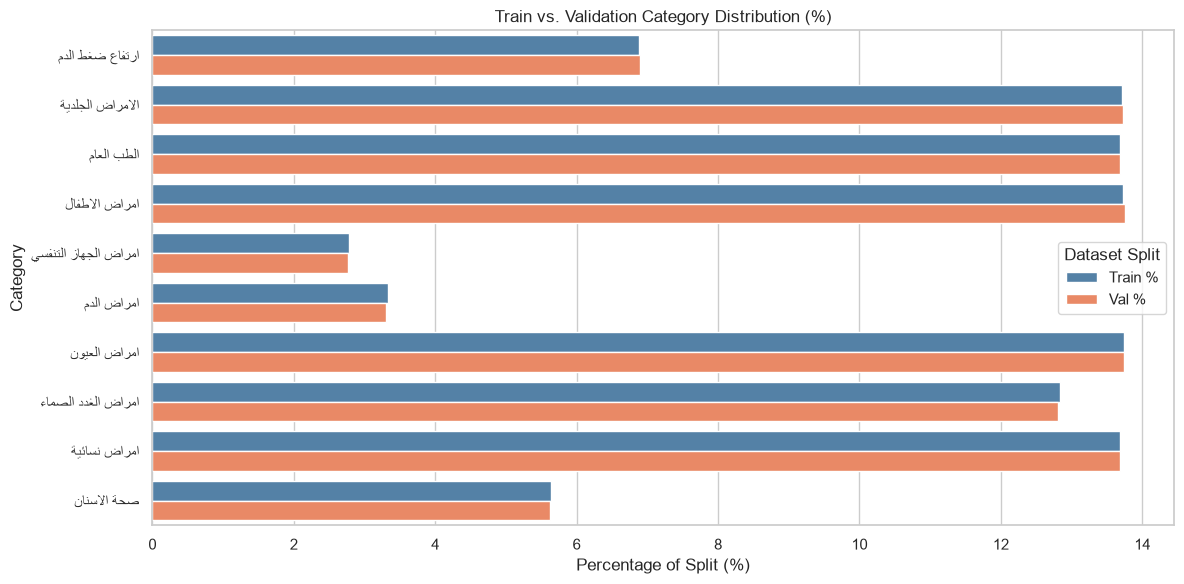

In [146]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def fix_arabic(text):
    return str(text)

def compare_train_val(train_df, val_df):
    # 1. Compute counts & percentages (fixing len(df) instead of len(train_df))
    train_counts = train_df["category"].value_counts()
    val_counts = val_df["category"].value_counts()
    
    comp_df = pd.DataFrame({
        "Train Count": train_counts,
        "Val Count": val_counts,
        "Train %": (train_counts / len(train_df) * 100).round(2),
        "Val %": (val_counts / len(val_df) * 100).round(2),
    })
    
    # Add difference column to verify stratification (should be close to 0.00%)
    comp_df["Diff % (Train - Val)"] = (comp_df["Train %"] - comp_df["Val %"]).round(2)
    
    # Add Ratio vs Smallest for both splits
    comp_df["Train IR"] = (train_counts / train_counts.min()).round(2)
    comp_df["Val IR"] = (val_counts / val_counts.min()).round(2)
    
    print("=== Summary Metrics ===")
    print(f"Train Total: {len(train_df):,} | Overall IR: {train_counts.max() / train_counts.min():.2f} : 1")
    print(f"Val Total:   {len(val_df):,} | Overall IR: {val_counts.max() / val_counts.min():.2f} : 1\n")
    
    display(comp_df)

    # 2. Side-by-Side Percentage Plot (Normalized so different split sizes compare fairly)
    plot_df = comp_df[["Train %", "Val %"]].reset_index().melt(
        id_vars="category", var_name="Split", value_name="Percentage"
    )
    # Fix Arabic text rendering for Matplotlib
    plot_df["category_ar"] = plot_df["category"].apply(fix_arabic)

    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=plot_df,
        x="Percentage",
        y="category_ar",
        hue="Split",
        palette=["steelblue", "coral"]
    )
    plt.title("Train vs. Validation Category Distribution (%)")
    plt.xlabel("Percentage of Split (%)")
    plt.ylabel("Category")
    plt.legend(title="Dataset Split")
    plt.tight_layout()
    plt.show()

# Run the comparison
compare_train_val(train_df, val_df)


In [147]:
train_categories = set(train_df["category"].dropna().unique())
val_categories = set(val_df["category"].dropna().unique())

print("Categories in training:", len(train_categories))
print("Categories in validation:", len(val_categories))

print("\nCategories only in training:")
print(train_categories - val_categories)

print("\nCategories only in validation:")
print(val_categories - train_categories)

Categories in training: 10
Categories in validation: 10

Categories only in training:
set()

Categories only in validation:
set()


In [148]:
train_questions = set(train_df["question"].dropna())
val_questions = set(val_df["question"].dropna())
test_questions = set(test_df["question"].dropna())

print("Train-Validation question overlap:",
      len(train_questions & val_questions))

print("Train-Test question overlap:",
      len(train_questions & test_questions))

print("Validation-Test question overlap:",
      len(val_questions & test_questions))

Train-Validation question overlap: 0
Train-Test question overlap: 3
Validation-Test question overlap: 0


### Observations 2 & Summary of what i did

- cleaned categories from train and val sets, they have lables containing 'أ' instaed of 'ا'
- after cleaning made sure that our duplicated questions did not change
- saw each split distrubtion, the samples are biased, top 6 categoies has around twice the 7th category, and around 5 times more than smallest category
- train and val splits have the same distribution
- no missing categories from each split
- we already know 3 questions from test set, but it wont affect the result that much so i will keep them


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Count</th>
      <th>Percentage</th>
    </tr>
    <tr>
      <th>category</th>
      <th></th>
      <th></th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>امراض العيون</th>
      <td>7988</td>
      <td>13.740432</td>
    </tr>
    <tr>
      <th>امراض الاطفال</th>
      <td>7986</td>
      <td>13.736991</td>
    </tr>
    <tr>
      <th>الامراض الجلدية</th>
      <td>7971</td>
      <td>13.711189</td>
    </tr>
    <tr>
      <th>الطب العام</th>
      <td>7954</td>
      <td>13.681947</td>
    </tr>
    <tr>
      <th>امراض نسائية</th>
      <td>7948</td>
      <td>13.671626</td>
    </tr>
    <tr>
      <th>امراض الغدد الصماء</th>
      <td>7462</td>
      <td>12.835641</td>
    </tr>
    <tr>
      <th>ارتفاع ضغط الدم</th>
      <td>3999</td>
      <td>6.878817</td>
    </tr>
    <tr>
      <th>صحة الاسنان</th>
      <td>3277</td>
      <td>5.636880</td>
    </tr>
    <tr>
      <th>امراض الدم</th>
      <td>1933</td>
      <td>3.325019</td>
    </tr>
    <tr>
      <th>امراض الجهاز التنفسي</th>
      <td>1617</td>
      <td>2.781457</td>
    </tr>
  </tbody>
</table>
</div>

### Label mapping

In [149]:
display(label_mapping_df.head(20))

print("Mapping columns:", label_mapping_df.columns.tolist())
print("Mapping shape:", label_mapping_df.shape)

,category,label_id
0,امراض العيون,0
1,الامراض الجلدية,1
2,الطب العام,2
3,امراض نسائية,3
4,امراض الغدد الصماء,4
5,امراض الاطفال,5
6,ارتفاع ضغط الدم,6
7,صحة الاسنان,7
8,امراض الدم,8
9,امراض الجهاز التنفسي,9


Mapping columns: ['category', 'label_id']
Mapping shape: (10, 2)


In [ ]:
LABEL_COL = "category"  
ID_COL = "label_id"     

print("Number of mapping entries:", len(label_mapping_df))

print("Duplicate category names:",
      label_mapping_df[LABEL_COL].duplicated().sum())

print("Duplicate label IDs:",
      label_mapping_df[ID_COL].duplicated().sum())

print("Categories missing from mapping:",
      train_categories - set(label_mapping_df[LABEL_COL]))

print("Extra categories in mapping:",
      set(label_mapping_df[LABEL_COL]) - train_categories)

Number of mapping entries: 10
Duplicate category names: 0
Duplicate label IDs: 0
Categories missing from mapping: set()
Extra categories in mapping: set()


### Sample verification

In [152]:
print("Submission columns:", sample_submission_df.columns.tolist())

print("Test IDs count:", len(test_df))
print("Submission IDs count:", len(sample_submission_df))

print(
    "IDs match:",
    test_df["id"].reset_index(drop=True).equals(
        sample_submission_df["id"].reset_index(drop=True)
    )
)

Submission columns: ['id', 'category']
Test IDs count: 7267
Submission IDs count: 7267
IDs match: True


TODO : text understanding, statistics 
-	تحليل الأسئلة واستكشاف طبيعة النصوص والأنماط اللغوية الموجودة فيها.
-	البحث عن الأسئلة المتكررة أو المتشابهة.
-	فحص النصوص بحثاً عن المشكلات التي قد تؤثر في عملية التدريب.
-	التحقق من وجود ضوضاء في البيانات.
- Preprocessing from the docx
- label mapping
- building baseline